# 02 — Inference & Model Understanding (CNN)

This notebook covers everything needed to understand and interrogate the trained model:

- **Architecture** — layer-by-layer summary table and a block diagram
- **WeightWatcher** — RMT-based health check on the weight matrices
- **Conv filters** — the spatial patterns L1 and L2 detect
- **Feature maps** — what those filters activate on a real digit
- **Grad-CAM** — which pixels in the input drove each prediction
- **Embedding scatter** — how the penultimate layer separates digit classes

**Run all cells top-to-bottom.** Notebook 01 must have run first.

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook --notebook-dir=image_nets/notebooks`

**What we do:** Imports, load best checkpoint, rebuild test set.
**Why:** Everything flows from `best_model.pt` — no in-memory state from notebook 01.
**What you should see:** Model printed, device, test set size.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import torch
import numpy as np
import matplotlib.pyplot as plt
import json
from torchvision import datasets, transforms

from tools.nets.cnn import SmallCNN
from tools.viz.filters      import plot_conv_filters
from tools.viz.feature_maps import plot_feature_maps
from tools.viz.gradcam      import gradcam, plot_gradcam_grid

FORCE_CPU = False
SEED      = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"
DATA_DIR      = ARTIFACTS_DIR / "mnist_data"

env    = json.loads((ARTIFACTS_DIR / "env.json").read_text())
config = json.loads((ARTIFACTS_DIR / "config.json").read_text())
N_CLASSES = config["n_classes"]

device = torch.device("cpu" if FORCE_CPU else env["device"])

ckpt  = torch.load(ARTIFACTS_DIR / "best_model.pt",
                   map_location=device, weights_only=False)
model = SmallCNN(N_CLASSES).to(device)
model.load_state_dict(ckpt["model_state"])
model.eval()

transform  = transforms.Compose([transforms.ToTensor(),
                                  transforms.Normalize((0.1307,),(0.3081,))])
test_set   = datasets.MNIST(DATA_DIR, train=False, download=False, transform=transform)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=512, shuffle=False)

print(model)
print(f"\ndevice    : {device}")
print(f"test set  : {len(test_set):,} samples")
print(f"best epoch: {ckpt['epoch']}")

SmallCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

device    : cuda
test set  : 10,000 samples
best epoch: 8


**What we do:** Print a detailed layer-by-layer summary table (input/output shapes,
parameter counts) using `torchinfo`, then draw a block diagram of the data flow.\n
**Why:** The summary table makes the architecture concrete — you can see exactly how
each tensor is reshaped. The block diagram gives the big picture at a glance.\n
**What you should see:** A table with one row per layer, then a horizontal flow diagram
showing tensor shapes at each stage.

Layer-by-layer architecture summary


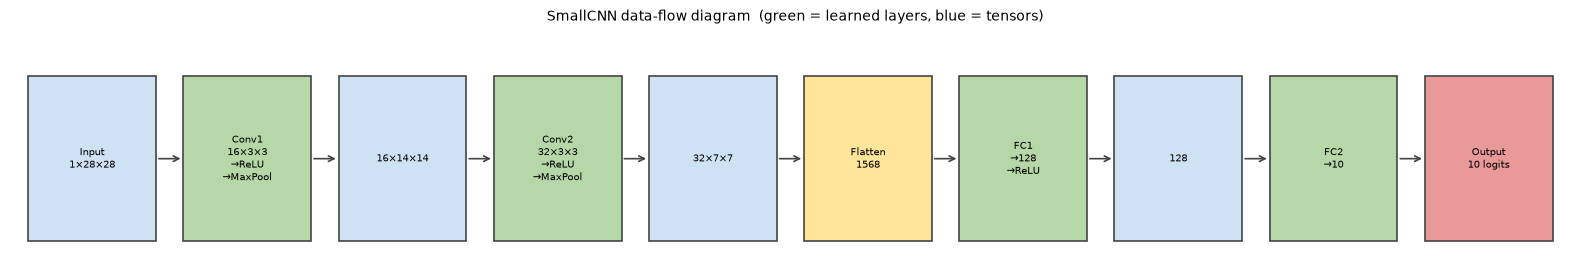

In [2]:
from torchinfo import summary as tinfo_summary

print("=" * 60)
print("Layer-by-layer architecture summary")
print("=" * 60)
tinfo_summary(model, input_size=(1, 1, 28, 28), device=device,
              col_names=["input_size", "output_size", "num_params", "kernel_size"],
              row_settings=["var_names"])

# ── block diagram ─────────────────────────────────────────────────────────────
blocks = [
    ("Input\n1×28×28", "#cfe2f3"),
    ("Conv1\n16×3×3\n→ReLU\n→MaxPool", "#b6d7a8"),
    ("16×14×14", "#cfe2f3"),
    ("Conv2\n32×3×3\n→ReLU\n→MaxPool", "#b6d7a8"),
    ("32×7×7", "#cfe2f3"),
    ("Flatten\n1568", "#ffe599"),
    ("FC1\n→128\n→ReLU", "#b6d7a8"),
    ("128", "#cfe2f3"),
    ("FC2\n→10", "#b6d7a8"),
    ("Output\n10 logits", "#ea9999"),
]

fig, ax = plt.subplots(figsize=(16, 2.8))
ax.axis("off")
bw, bh, gap = 1.4, 1.8, 0.3
x = 0
for label, color in blocks:
    rect = plt.Rectangle((x, 0), bw, bh, facecolor=color, edgecolor="#444", lw=1.2)
    ax.add_patch(rect)
    ax.text(x + bw / 2, bh / 2, label, ha="center", va="center",
            fontsize=7.5, multialignment="center")
    if x > 0:
        ax.annotate("", xy=(x, bh / 2), xytext=(x - gap, bh / 2),
                    arrowprops=dict(arrowstyle="->", color="#444", lw=1.2))
    x += bw + gap

ax.set_xlim(-0.2, x)
ax.set_ylim(-0.3, bh + 0.3)
fig.suptitle("SmallCNN data-flow diagram  (green = learned layers, blue = tensors)",
             fontsize=10)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "architecture_diagram.png", dpi=120, bbox_inches="tight")
plt.show()

**What we do:** Plot the learned conv filters for `conv1` and `conv2`.
**Why:** Layer-1 filters in a CNN trained on images typically resemble Gabor filters — oriented edges, corners, blobs. Layer-2 filters are harder to interpret directly because they operate on 16-channel feature maps, so we average over input channels.
**What you should see:** Small 3×3 patterns; many L1 filters will look like oriented edge detectors.

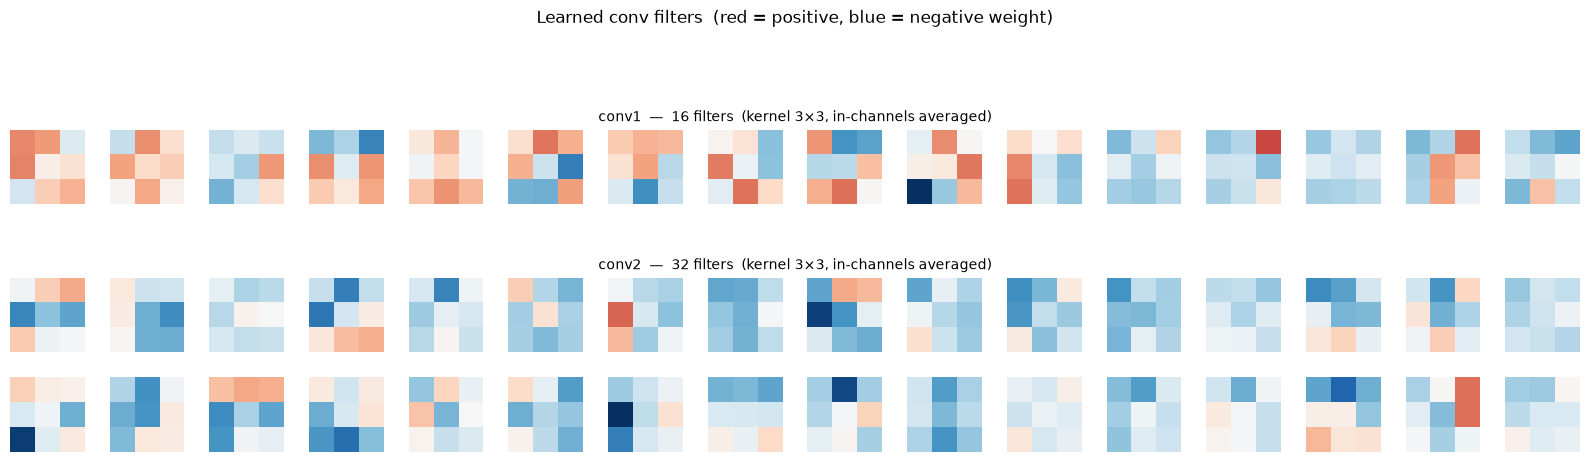

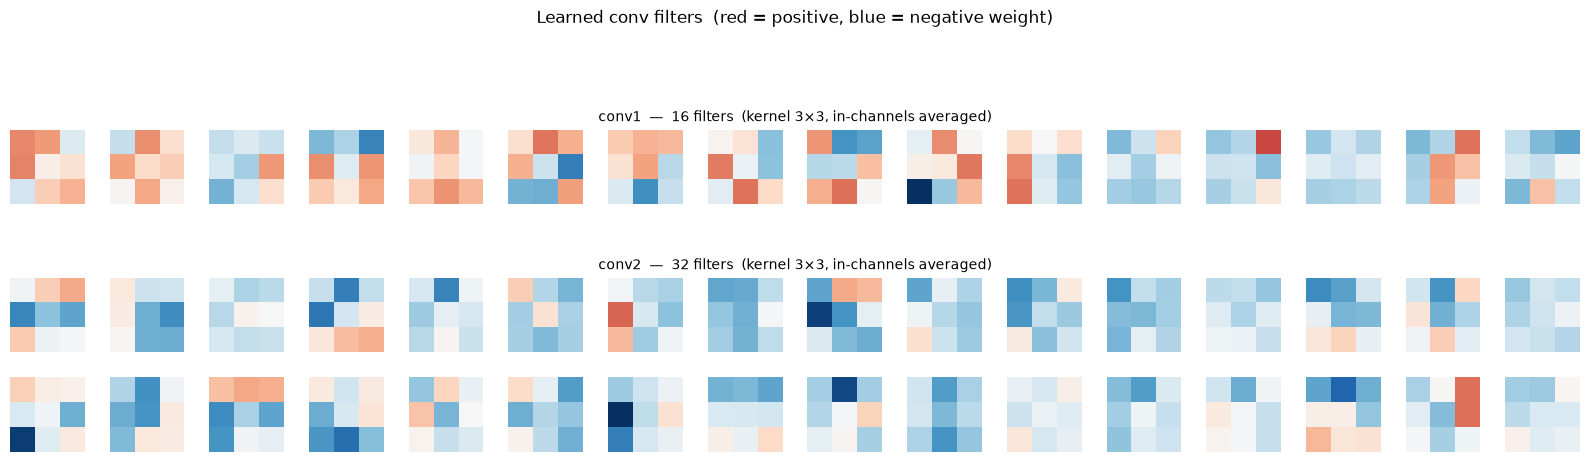

In [3]:
plot_conv_filters(model, save_path=ARTIFACTS_DIR / "conv_filters.png")

**What we do:** Pick one example of each digit class and display the feature maps after `conv1` and `conv2`.
**Why:** The feature maps show *where in the image* each filter fires — bright = strong activation. This is the 'what does layer N see' view.
**What you should see:** Conv1 maps highlighting edges; conv2 maps highlighting higher-level parts.

Showing feature maps for digit '3'


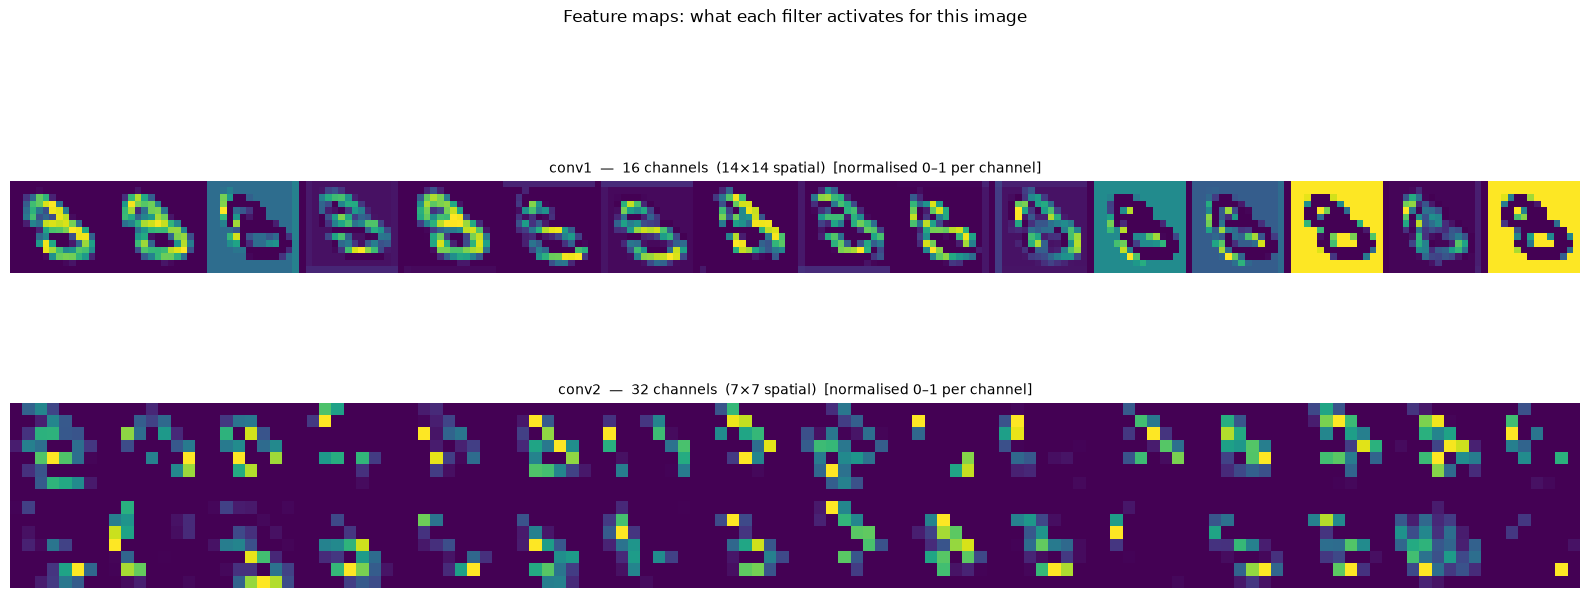

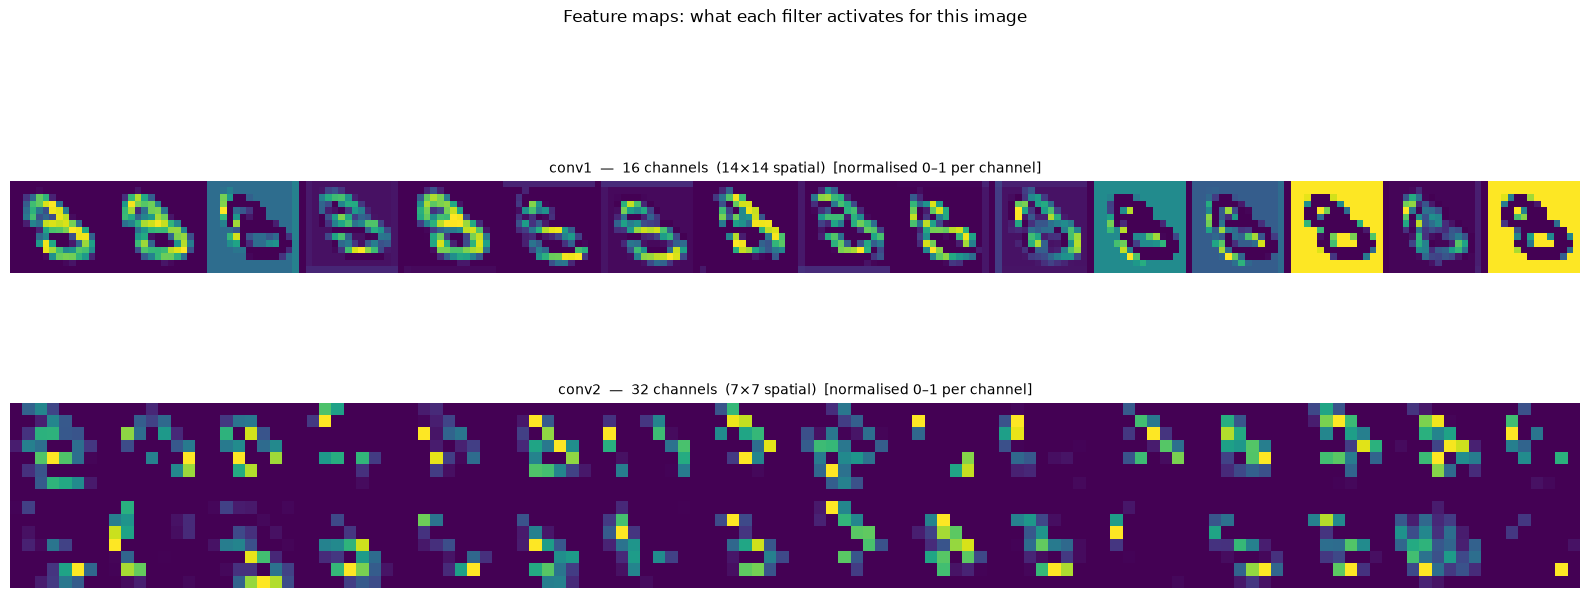

In [4]:
class_names = [str(i) for i in range(N_CLASSES)]

# grab one example per digit
examples = {}
for img, label in test_set:
    if label not in examples:
        examples[label] = img
    if len(examples) == N_CLASSES:
        break

digit = 3   # change this to see a different class
print(f"Showing feature maps for digit '{digit}'")
plot_feature_maps(model, examples[digit], device,
                  save_path=ARTIFACTS_DIR / f"feature_maps_digit{digit}.png")

**What we do:** Show feature maps for three more digits side-by-side for comparison.
**Why:** Comparing the activation patterns across different digits reveals which filters are class-specific vs. universal (e.g., all digits activate edge detectors, but loop detectors fire only for 0, 6, 8, 9).
**What you should see:** Qualitatively different patterns per digit.

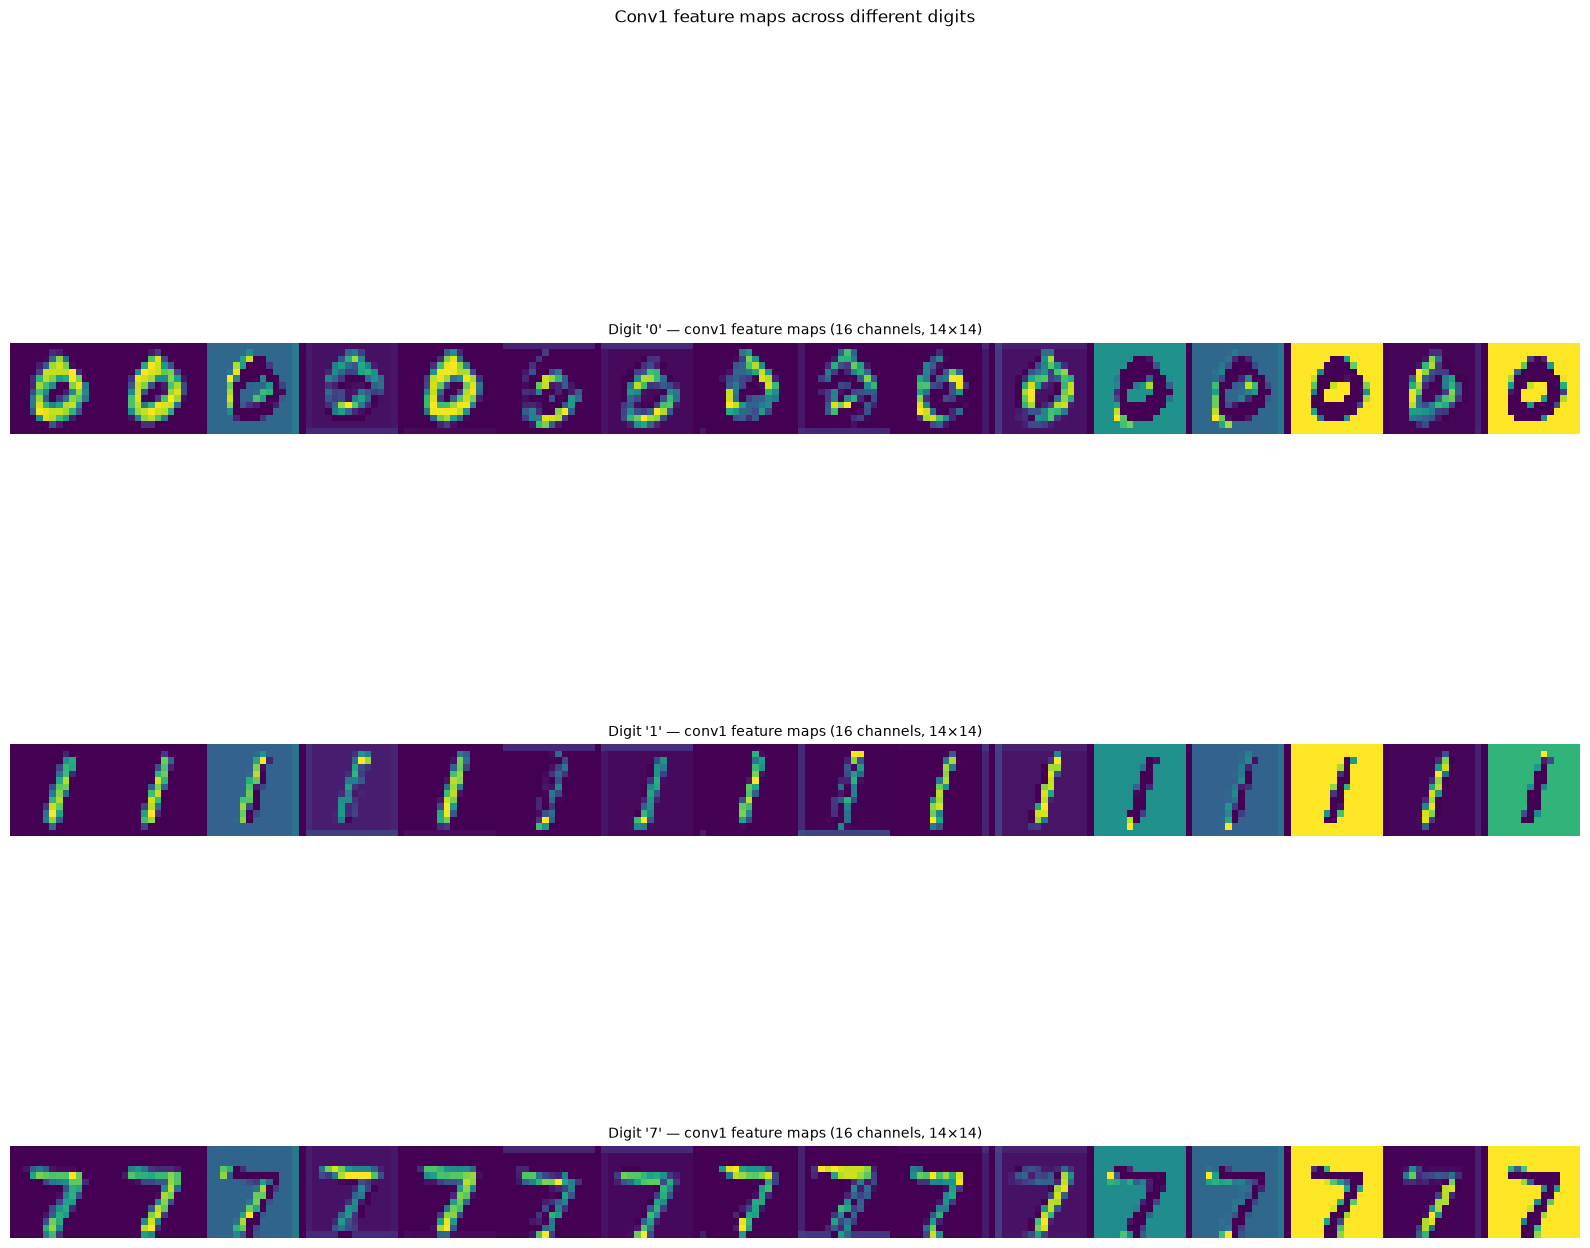

In [5]:
compare_digits = [0, 1, 7]
fig, all_axes = plt.subplots(len(compare_digits), 1, figsize=(16, 5 * len(compare_digits)))

for ax_row, d in zip(all_axes, compare_digits):
    store = {}
    h = model.conv1.register_forward_hook(lambda m,i,o: store.update({"c1": o}))
    with torch.no_grad():
        model(examples[d].unsqueeze(0).to(device))
    h.remove()

    acts = store["c1"][0].cpu().numpy()    # (16, 14, 14)
    H, W = acts.shape[1], acts.shape[2]
    cols = 16
    grid = np.zeros((H, cols * (W + 1) - 1))
    for k in range(cols):
        c0 = k * (W + 1)
        a  = acts[k]
        a  = (a - a.min()) / (a.max() - a.min() + 1e-8)
        grid[:, c0:c0 + W] = a

    ax_row.imshow(grid, cmap="viridis"); ax_row.axis("off")
    ax_row.set_title(f"Digit '{d}' — conv1 feature maps (16 channels, 14×14)", fontsize=10)

fig.suptitle("Conv1 feature maps across different digits", y=1.01)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "feature_maps_comparison.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Apply Grad-CAM to 8 test images — the heatmap highlights which pixels in the input contributed most to the model's prediction.
**Why:** Grad-CAM answers 'why did the model predict this class?' It is the standard tool for CNN explainability. For a digit classifier the highlighted region should match the digit strokes, not the background.
**What you should see:** 8 rows of (original | heatmap | overlay); the heatmap should roughly outline the digit.

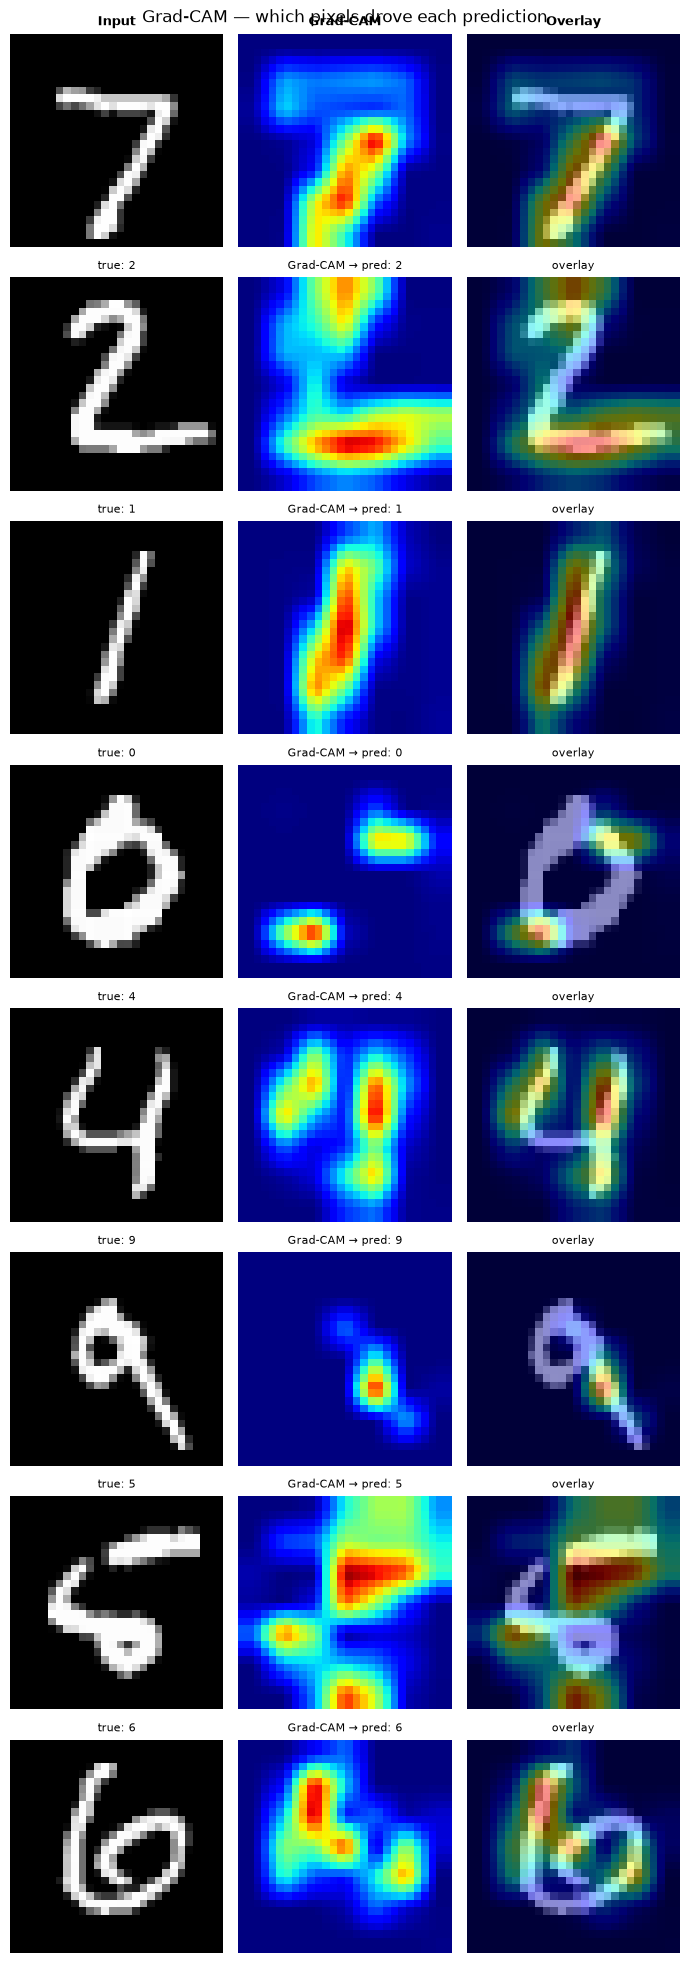

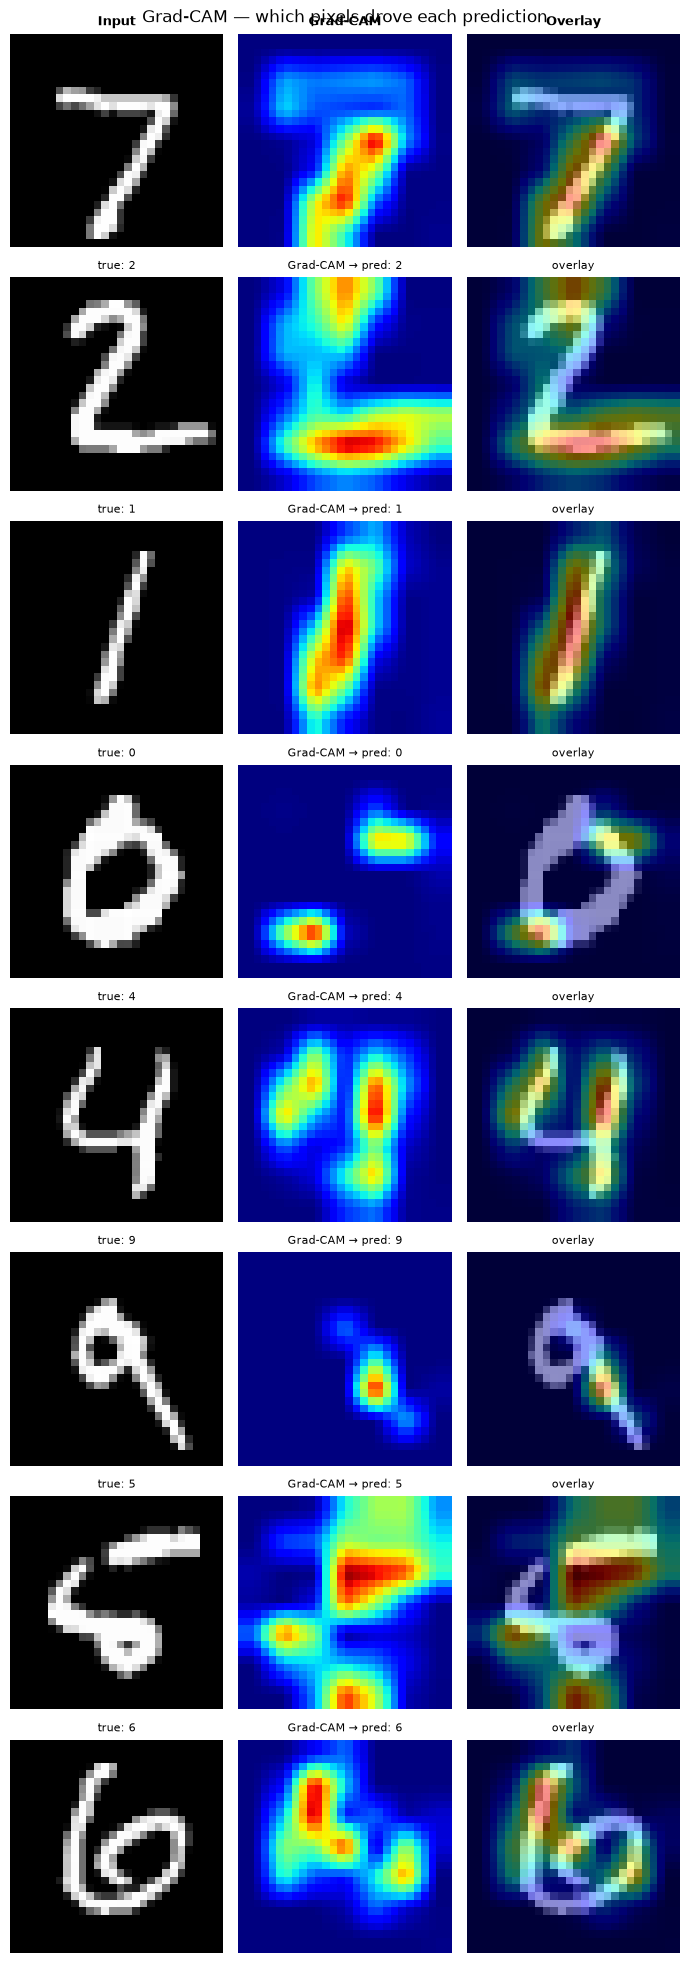

In [6]:
# grab 8 test images covering different digits
sample_imgs   = []
sample_labels = []
seen = set()
for img, label in test_set:
    if label not in seen:
        sample_imgs.append(img)
        sample_labels.append(label)
        seen.add(label)
    if len(seen) == 8:
        break

imgs_t   = torch.stack(sample_imgs)
labels_t = torch.tensor(sample_labels)

plot_gradcam_grid(
    model, imgs_t, labels_t, device,
    class_names=class_names, n=8,
    save_path=ARTIFACTS_DIR / "gradcam.png",
)

**What we do:** Extract the 128-dimensional penultimate layer (before `fc2`) for all 10k test images, then reduce to 2D with PCA and scatter-plot, coloured by digit class.
**Why:** This is the CNN's internal representation of each digit. If the 10 digit classes form distinct clusters, the model has learned discriminative features. Overlap between clusters predicts confusion between classes.
**What you should see:** 10 tight, well-separated clusters.

Embedding shape : (10000, 128)
PCA variance explained: PC1=0.193  PC2=0.172  total=0.365


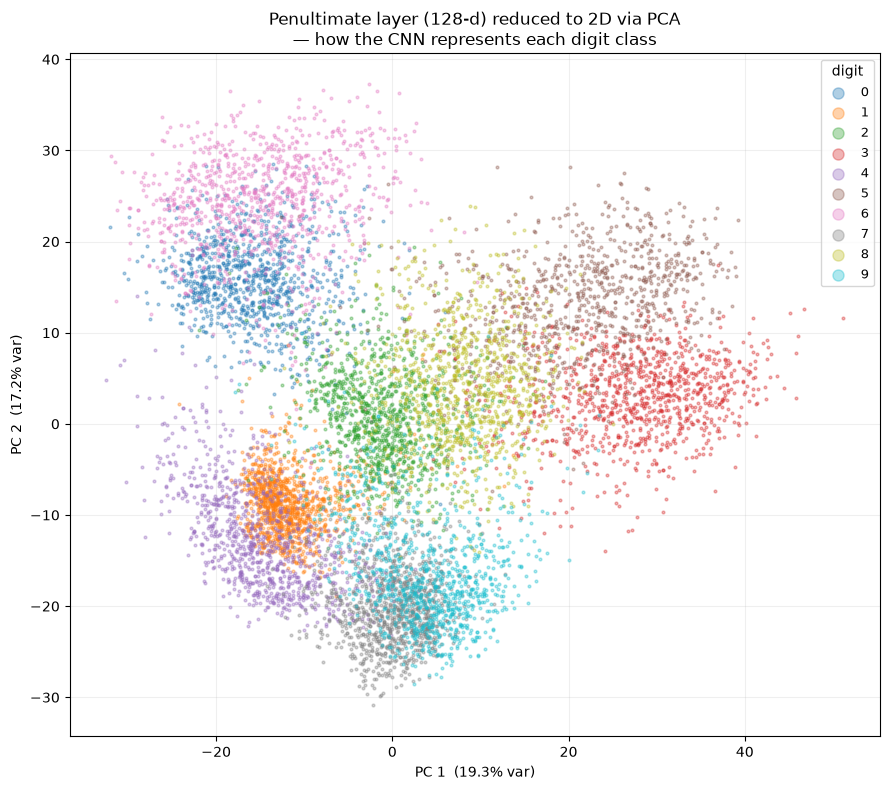

In [7]:
from sklearn.decomposition import PCA

embeddings  = []
true_labels = []

store_emb = {}
h = model.relu3.register_forward_hook(
    lambda m, i, o: store_emb.update({"emb": o.detach().cpu()})
)

model.eval()
with torch.no_grad():
    for X, y in test_loader:
        _ = model(X.to(device))
        embeddings.append(store_emb["emb"].numpy())
        true_labels.extend(y.numpy())

h.remove()

E = np.vstack(embeddings)
L = np.array(true_labels)

pca = PCA(n_components=2, random_state=SEED)
E2  = pca.fit_transform(E)
var = pca.explained_variance_ratio_

print(f"Embedding shape : {E.shape}")
print(f"PCA variance explained: PC1={var[0]:.3f}  PC2={var[1]:.3f}  total={var.sum():.3f}")

fig, ax = plt.subplots(figsize=(9, 8))
cmap = plt.colormaps["tab10"].resampled(N_CLASSES)
for cls in range(N_CLASSES):
    mask = L == cls
    ax.scatter(E2[mask, 0], E2[mask, 1], s=4, alpha=0.35,
               color=cmap(cls), label=str(cls))

ax.legend(markerscale=4, fontsize=9, title="digit")
ax.set_xlabel(f"PC 1  ({var[0]*100:.1f}% var)")
ax.set_ylabel(f"PC 2  ({var[1]*100:.1f}% var)")
ax.set_title("Penultimate layer (128-d) reduced to 2D via PCA\n"
             "— how the CNN represents each digit class")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "embedding_pca.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Find the test images the model was most confused about — highest softmax entropy — and display them.
**Why:** High-entropy predictions indicate ambiguous images (noisy, unusual handwriting). Seeing what confuses the model calibrates your trust in it.
**What you should see:** Blurry or oddly-written digits that even a human might find hard to classify.

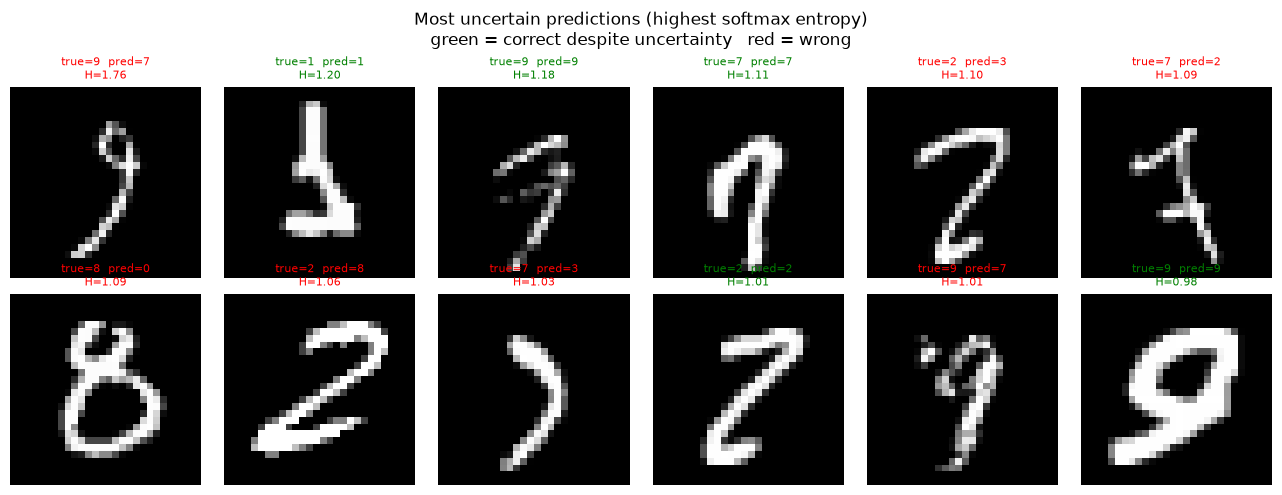

In [8]:
import torch.nn.functional as F

entropies = []
all_preds = []

model.eval()
with torch.no_grad():
    for X, y in test_loader:
        out   = model(X.to(device))
        probs = F.softmax(out, dim=1).cpu()
        ent   = -(probs * probs.log().clamp(min=-20)).sum(dim=1)
        entropies.append(ent)
        all_preds.append(out.argmax(1).cpu())

entropies = torch.cat(entropies).numpy()
all_preds = torch.cat(all_preds).numpy()
all_imgs  = torch.stack([test_set[i][0] for i in range(len(test_set))])
all_labs  = np.array([test_set[i][1] for i in range(len(test_set))])

top12 = np.argsort(entropies)[::-1][:12]

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, idx in zip(axes.flat, top12):
    img = all_imgs[idx][0].numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    ax.imshow(img, cmap="gray")
    correct = all_preds[idx] == all_labs[idx]
    color   = "green" if correct else "red"
    ax.set_title(f"true={all_labs[idx]}  pred={all_preds[idx]}\n"
                 f"H={entropies[idx]:.2f}", fontsize=8, color=color)
    ax.axis("off")

fig.suptitle("Most uncertain predictions (highest softmax entropy)\n"
             "green = correct despite uncertainty   red = wrong")
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "confused_samples.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Run WeightWatcher on every layer to check model health using Random Matrix Theory (RMT).
**Why:** WeightWatcher fits a power-law `ρ(λ) ∝ λ⁻ᵅ` to each weight matrix's eigenvalue spectrum. A well-trained layer has alpha ≈ 2–4 (bulk+tail). Alpha < 2 → under-trained; alpha > 6 → over-compressed or poorly regularised. This is a post-training diagnostic — no data needed.
**What you should see:** A table of alpha values per layer; fc1 and fc2 should fall in the healthy 2–4 range. Conv layers (3×3 kernels) are too small for reliable RMT analysis so WeightWatcher may skip or flag them.

In [9]:
import weightwatcher as ww

watcher = ww.WeightWatcher(model=model)
details = watcher.analyze(plot=False)

print("\nWeightWatcher layer analysis")
print("-" * 55)
cols = ["name", "alpha", "alpha_weighted", "norm", "log_norm"]
available = [c for c in cols if c in details.columns]
print(details[available].to_string(index=False))

print("\n--- Summary ---")
summary = watcher.get_summary(details)
for k, v in summary.items():
    if isinstance(v, float):
        print(f"  {k:<25} {v:.4f}")
    else:
        print(f"  {k:<25} {v}")

healthy = details[details["alpha"].between(2, 6)] if "alpha" in details.columns else details
print(f"\nLayers with alpha in healthy range [2,6]: {len(healthy)} / {len(details)}")

assert len(details) > 0, "FAIL: WeightWatcher returned no layers"
print("PASS: WeightWatcher analysis complete")

SMALL N PL FIT
SMALL N PL FIT

WeightWatcher layer analysis
-------------------------------------------------------
name    alpha  alpha_weighted       norm  log_norm
   0 2.489312       -0.070821   5.837520  0.766228
   0 1.639212       -0.186307  22.041014  1.343232
 fc1 1.801064        2.797390 340.425832  2.532023
 fc2 2.882807        0.597883  10.135463  1.005844

--- Summary ---
  log_norm                  1.4118
  alpha                     2.2031
  alpha_weighted            0.7845
  log_alpha_norm            1.5581
  log_spectral_norm         0.4046
  stable_rank               12.6696

Layers with alpha in healthy range [2,6]: 2 / 4
PASS: WeightWatcher analysis complete
